In [69]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_blobs, make_moons, make_circles, make_classification
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

In [70]:
data = pd.read_csv('german_credit_data.csv', sep=',')

In [71]:
data.head(5)

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


In [72]:
data.shape

(1000, 10)

In [73]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
dtypes: int64(5), str(5)
memory usage: 78.3 KB


In [74]:
data.dtypes

Unnamed: 0          int64
Age                 int64
Sex                   str
Job                 int64
Housing               str
Saving accounts       str
Checking account      str
Credit amount       int64
Duration            int64
Purpose               str
dtype: object

In [75]:
data.describe()

,Unnamed: 0,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


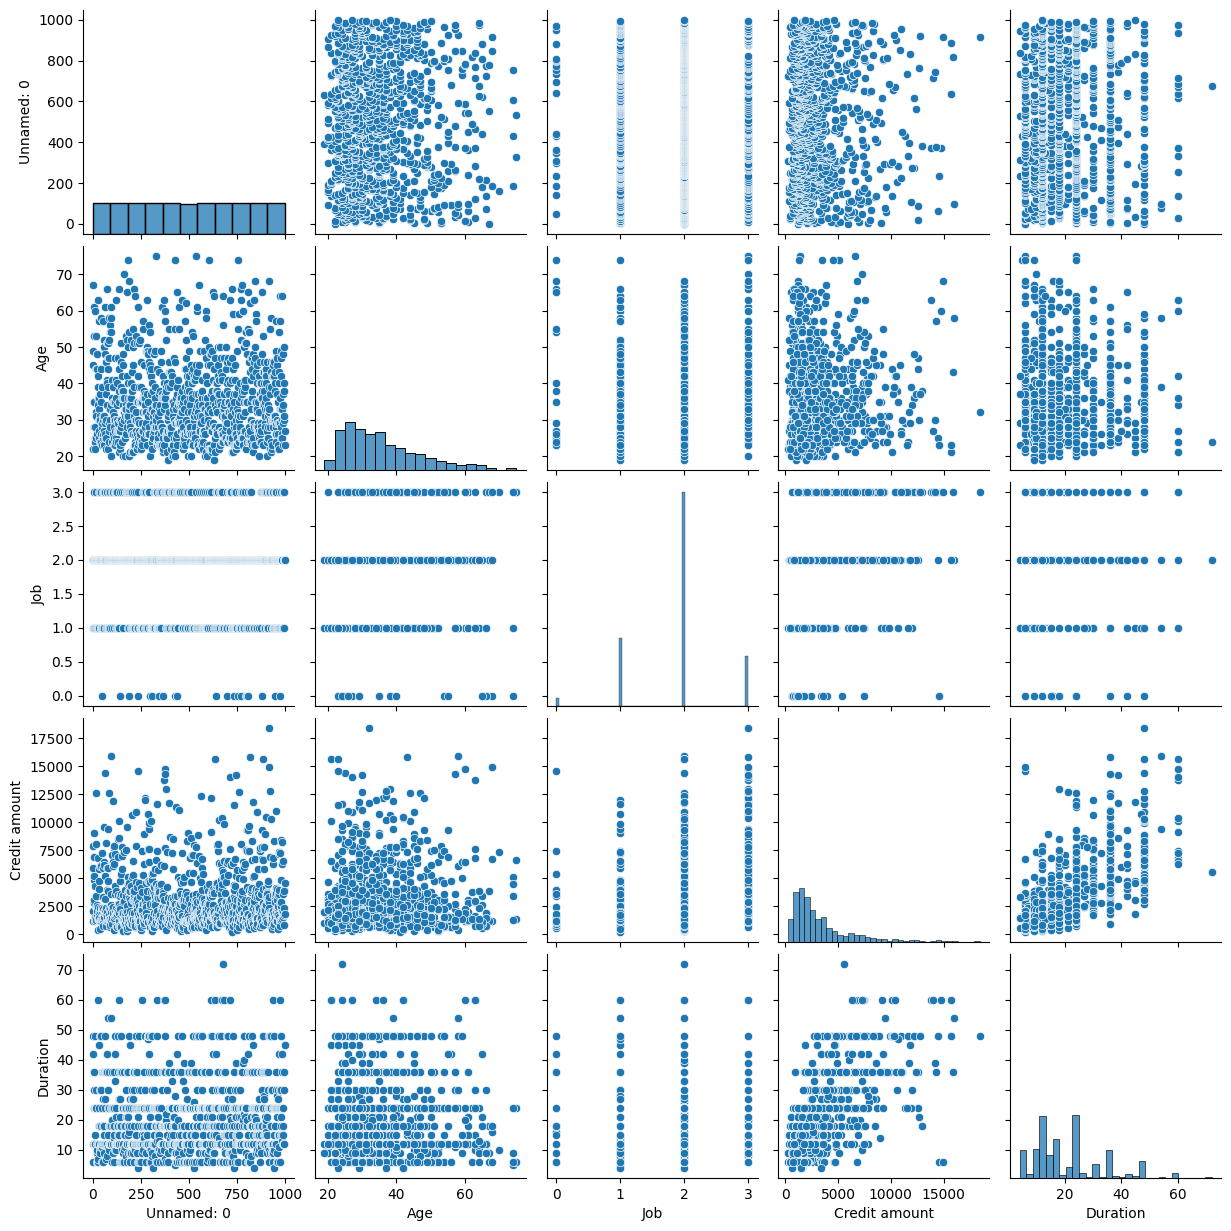

In [76]:
data.select_dtypes('number').corr()

sns.pairplot(data);

In [77]:
data.isnull().sum() 

Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64

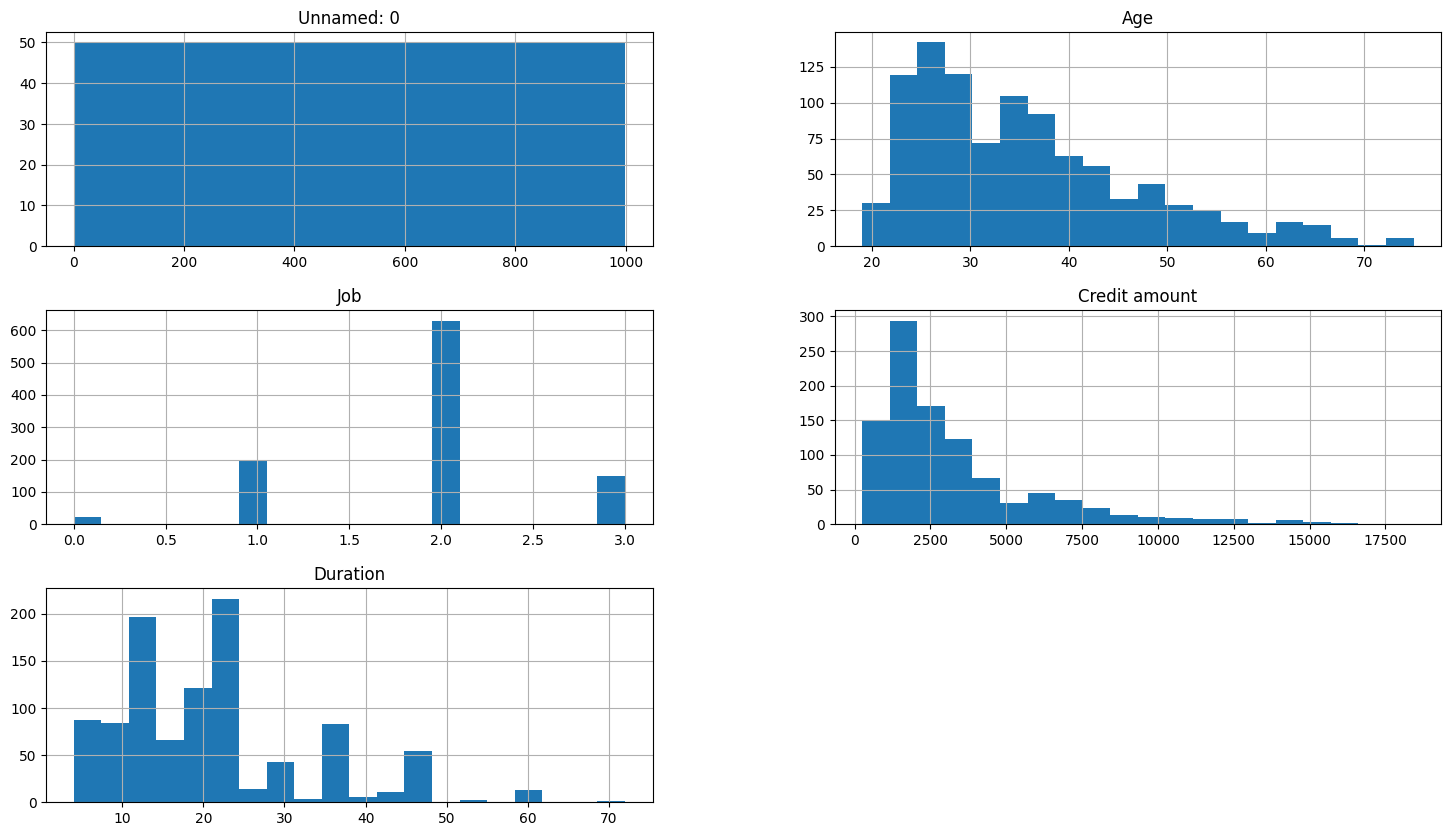

In [78]:
data.hist(figsize=(18, 10), bins=20);

In [79]:
# df_raw - исходные признаки, понадобится для описания кластеров (средние, моды, доли)
df_raw = data.drop(columns=['Unnamed: 0']).copy()

df_raw['Saving accounts'] = df_raw['Saving accounts'].fillna('unknown')
df_raw = df_raw.drop(columns=['Checking account'])  # 39% NaN - отбрасываем

# df - таблица для моделирования (one-hot)
df = pd.get_dummies(df_raw, columns=['Sex', 'Job', 'Housing', 'Saving accounts', 'Purpose'], drop_first=True)

from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(df)

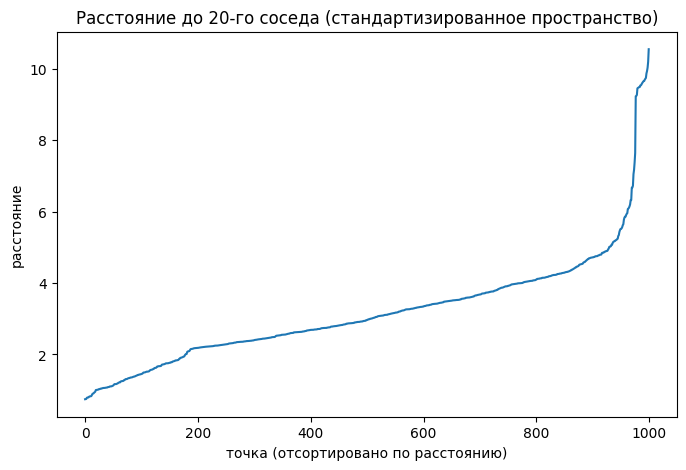

p25=2.29, медиана=2.96, p75=3.92, max=10.55
eps = 2.29


In [80]:
# Подбор eps: расстояние до 20-го соседа (для min_samples=20)
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=20)
nn.fit(X)
dist, _ = nn.kneighbors(X)
dist = np.sort(dist[:, -1], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(dist)
plt.title('Расстояние до 20-го соседа (стандартизированное пространство)')
plt.xlabel('точка (отсортировано по расстоянию)')
plt.ylabel('расстояние')
plt.show()

print(f"p25={np.percentile(dist, 25):.2f}, медиана={np.median(dist):.2f}, p75={np.percentile(dist, 75):.2f}, max={dist.max():.2f}")

# "Локоть" кривой находится около 2.3-2.5; берем 25-й перцентиль как автоматическую оценку
eps = float(np.percentile(dist, 25))
print(f"eps = {eps:.2f}")

In [81]:
corr = data.corr(numeric_only=True)

In [82]:
mask = np.triu(np.ones_like(corr, dtype=bool))

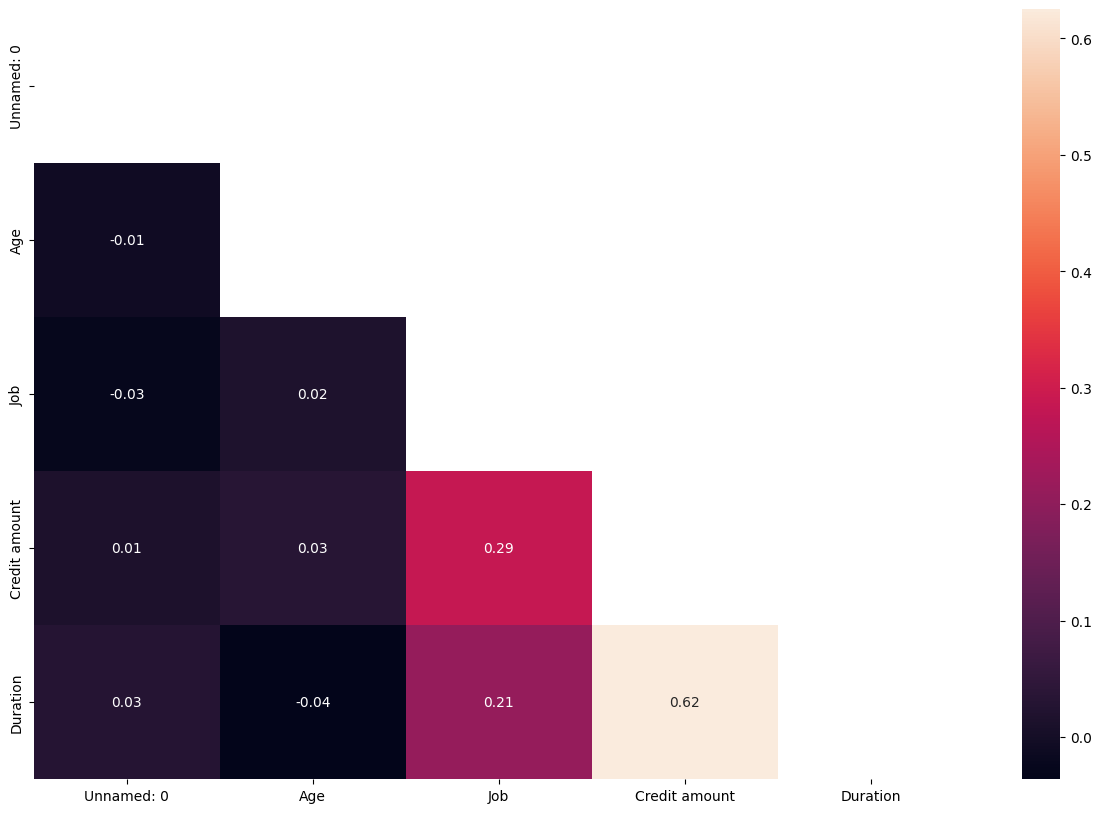

In [83]:
plt.figure(figsize=(15,10))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f');

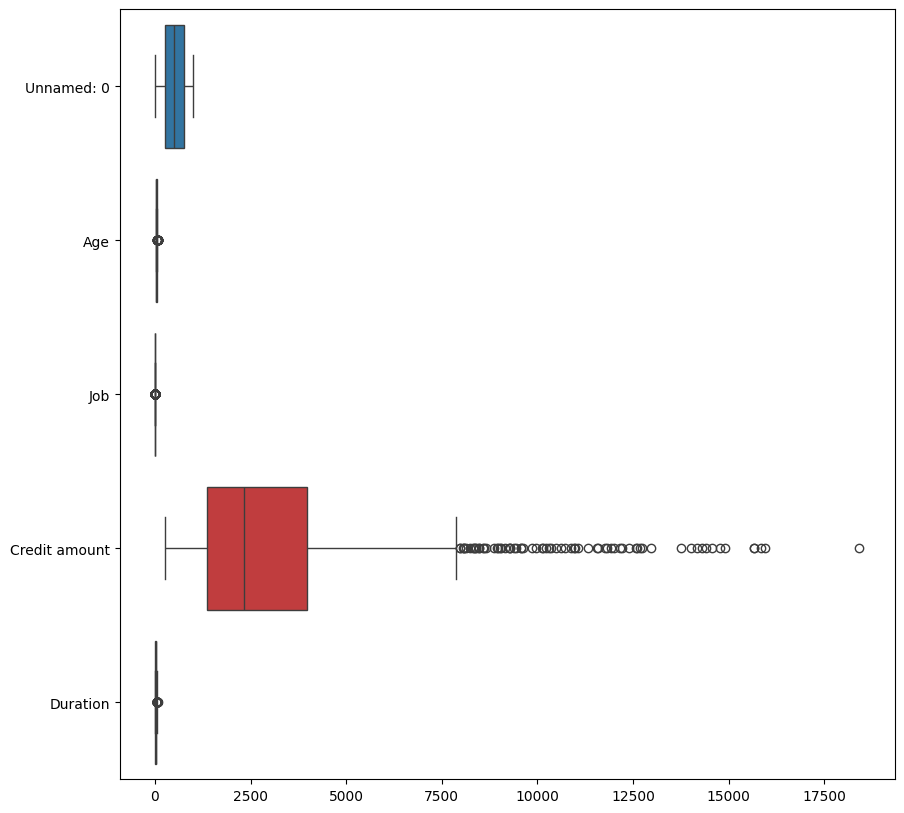

In [84]:
plt.figure(figsize=(10,10))
sns.boxplot(data=data, orient='h');

In [85]:
from sklearn.preprocessing import MinMaxScaler

In [86]:
scaler = MinMaxScaler()

In [87]:
X_scaled = scaler.fit_transform(df)

In [88]:
data_scaled = pd.DataFrame(X_scaled, columns=df.columns)

In [89]:
data_scaled.head()

,Age,Credit amount,Duration,Sex_male,Job_1,Job_2,Job_3,Housing_own,Housing_rent,Saving accounts_moderate,Saving accounts_quite rich,Saving accounts_rich,Saving accounts_unknown,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,0.857143,0.050567,0.029412,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.053571,0.313690,0.647059,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.535714,0.101574,0.117647,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.464286,0.419941,0.558824,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0.607143,0.254209,0.294118,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


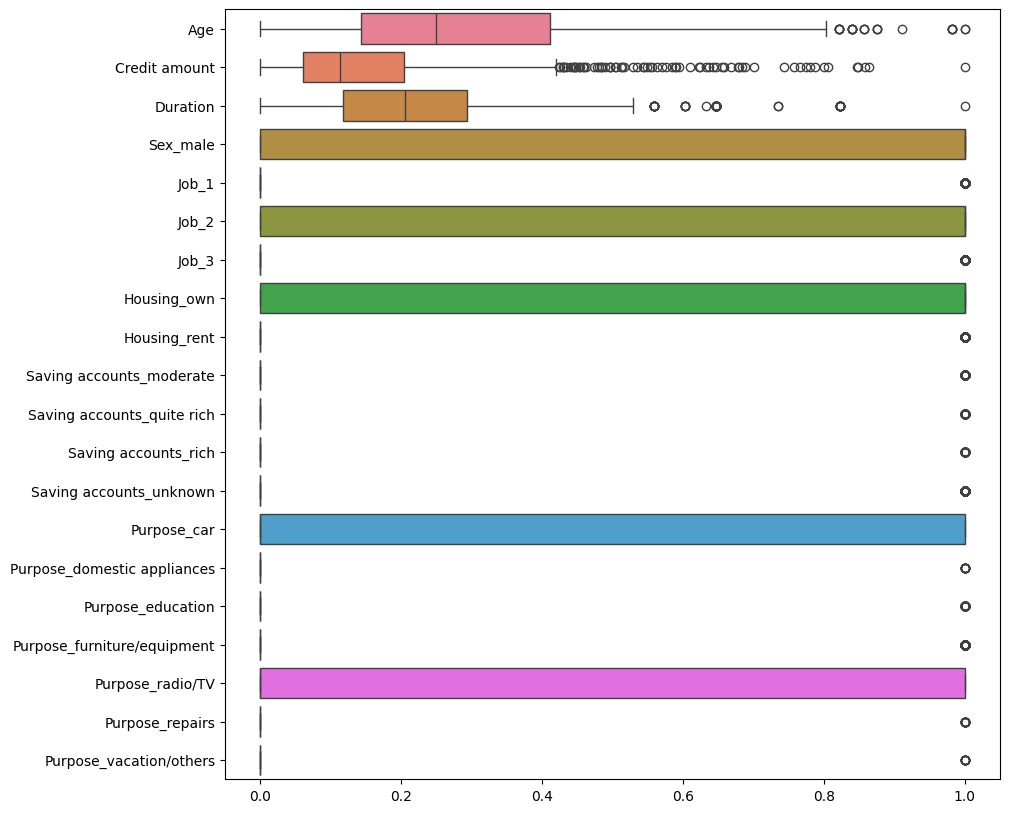

In [90]:
plt.figure(figsize=(10,10))
sns.boxplot(data=data_scaled, orient='h');

In [91]:
from sklearn.manifold import TSNE

In [92]:
tsne = TSNE(n_components=2, random_state=10)

In [93]:
X_scaled.shape

(1000, 20)

In [94]:
X_tsne = tsne.fit_transform(X_scaled)

In [95]:
X_tsne.shape

(1000, 2)

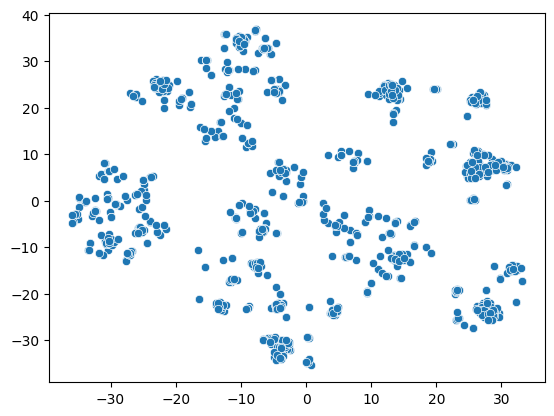

In [96]:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1]);

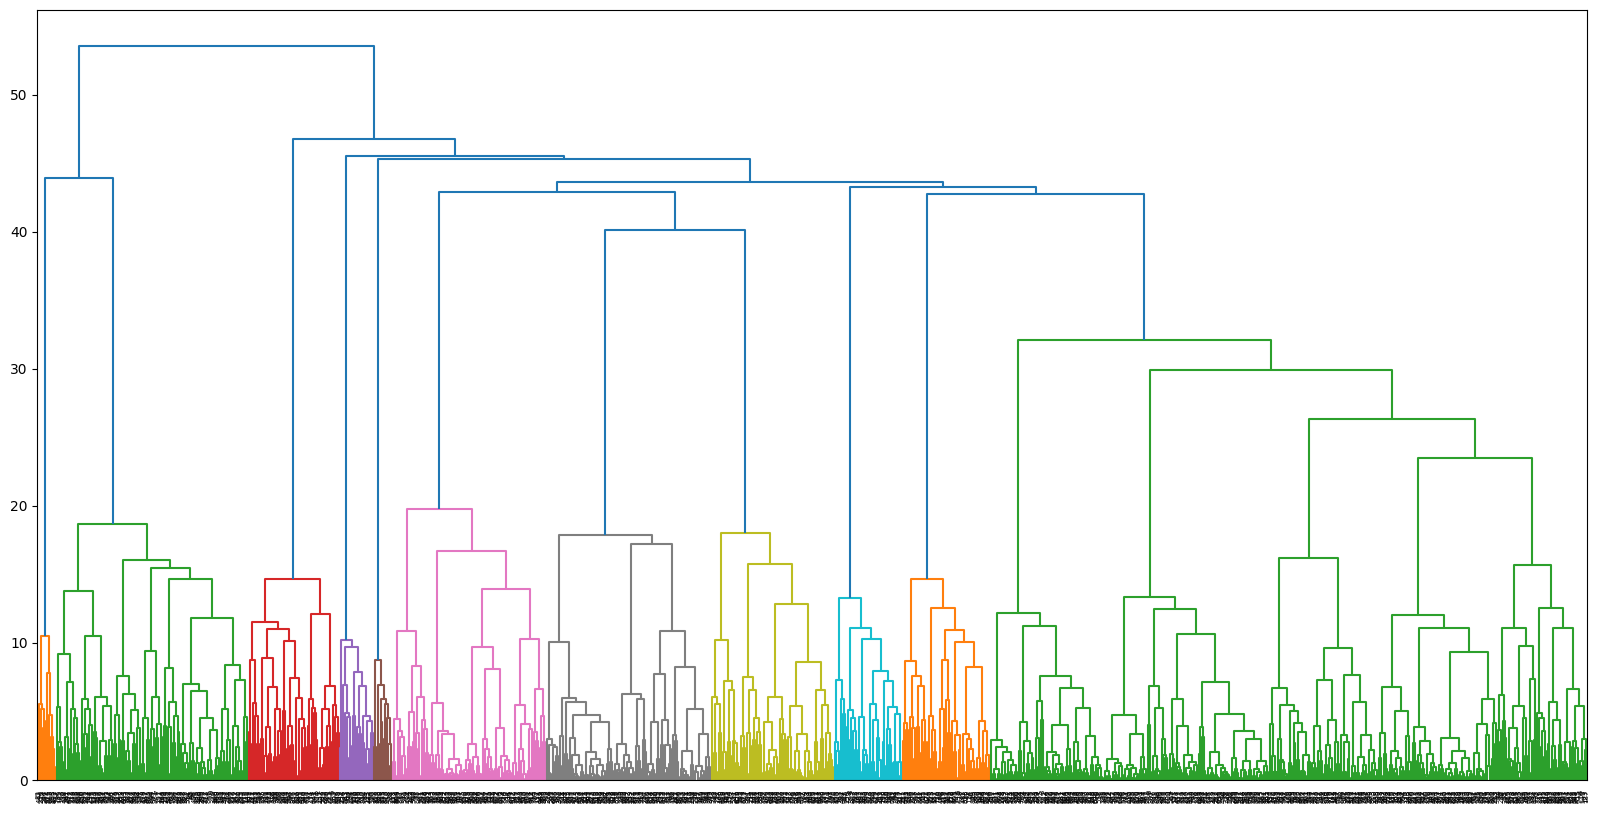

In [97]:
plt.figure(figsize=(20,10))
linkage_ = linkage(X, method='ward')
dendrogram_ = dendrogram(linkage_)

In [98]:
def dbscan_clustering(eps_range, X, min_samples=20):
    """Сканирует eps: строит кривые silhouette и числа кластеров.

    Возвращает массивы (eps, silhouette, n_clusters, n_noise) для последующего анализа.
    """
    silhouette = []
    clusters = []
    noise = []
    for i in tqdm(eps_range):
        labels = DBSCAN(eps=i, min_samples=min_samples).fit(X).labels_
        n_clusters = len(np.unique(labels[labels != -1]))
        score = silhouette_score(X, labels) if n_clusters > 1 else 0.0
        silhouette.append(score)
        clusters.append(n_clusters)
        noise.append(int((labels == -1).sum()))

    fig, ax1 = plt.subplots()

    color = 'tab:red'
    ax1.plot(eps_range, silhouette, marker='o', color=color)
    ax1.set_xlabel('eps')
    ax1.set_ylabel('silhouette', color=color)
    ax1.tick_params(axis='y', labelcolor=color)

    ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

    color = 'tab:blue'
    ax2.plot(eps_range, clusters, marker='o', color=color)
    ax2.set_ylabel('n_clusters', color=color)
    ax2.tick_params(axis='y', labelcolor=color)

    fig.tight_layout()  # otherwise the right y-label is slightly clipped
    plt.show()

    return eps_range, np.array(silhouette), np.array(clusters), np.array(noise)

100%|██████████| 90/90 [00:00<00:00, 147.26it/s]


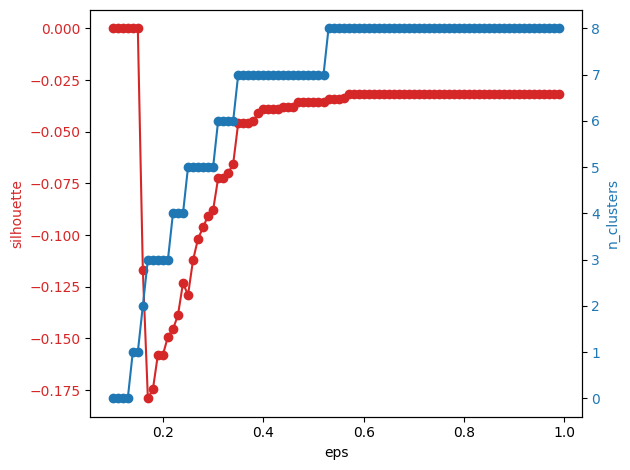

(array([0.1 , 0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 ,
        0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31,
        0.32, 0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42,
        0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53,
        0.54, 0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64,
        0.65, 0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75,
        0.76, 0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86,
        0.87, 0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97,
        0.98, 0.99]),
 array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        , -0.11699502, -0.17894459, -0.17467294, -0.15787423,
        -0.15787423, -0.14914047, -0.14560357, -0.13863089, -0.12325365,
        -0.12899759, -0.11215969, -0.10171704, -0.09628781, -0.0905227 ,
        -0.08787361, -0.07255299, -0.07255299, -0.07004536, -0.06549458,
        -0.04586214, 

In [99]:
eps_range = np.arange(0.1,1,0.01)
dbscan_clustering(eps_range, X_scaled)

In [100]:
silhouette = []
for i in tqdm(range(2,11)):
    agg = AgglomerativeClustering(n_clusters=i).fit(X)
    labels = agg.labels_
    score = silhouette_score(X, labels)
    silhouette.append(score)

100%|██████████| 9/9 [00:00<00:00, 77.71it/s]


Text(0.5, 1.0, 'Кластеры в t-SNE пространстве (Agglomerative, n_clusters=10)')

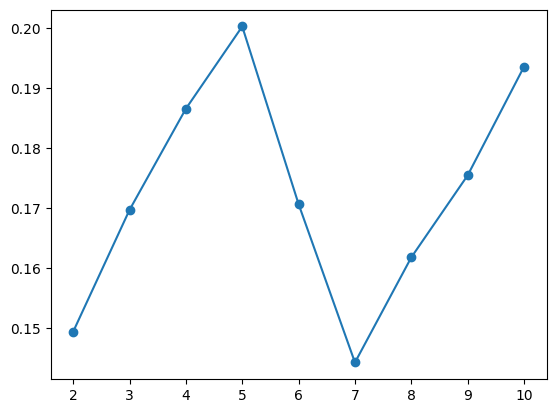

In [101]:
plt.plot(range(2,11), silhouette, marker='o');
ax.set_title(f"Кластеры в t-SNE пространстве (Agglomerative, n_clusters={len(np.unique(labels))})")


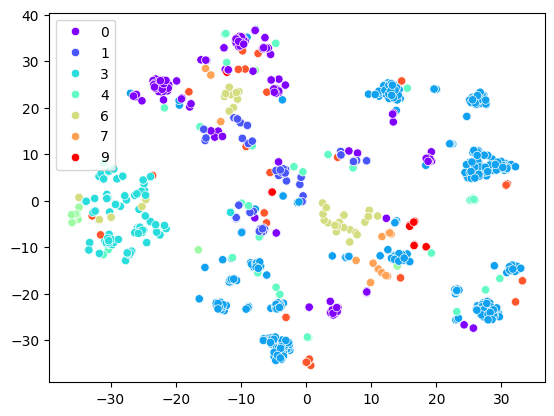

In [102]:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=labels, palette='rainbow');

In [103]:
data['labels'] = labels

In [104]:
data['labels'].value_counts(normalize=True)

labels
2    0.385
0    0.186
3    0.124
1    0.099
6    0.059
4    0.057
8    0.044
7    0.022
9    0.012
5    0.012
Name: proportion, dtype: float64

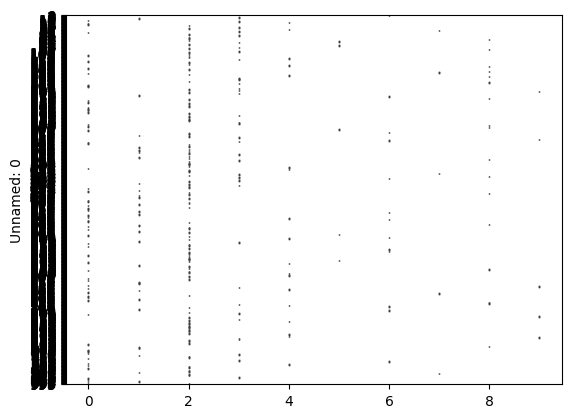

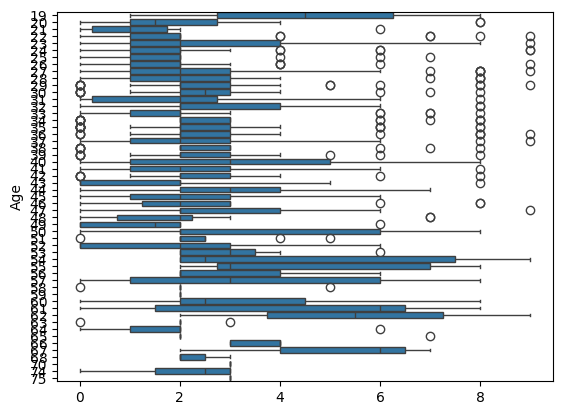

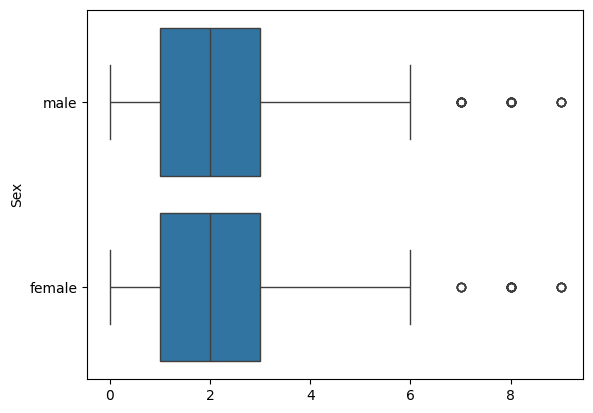

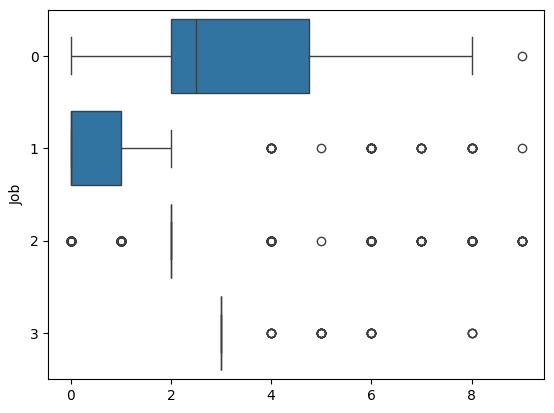

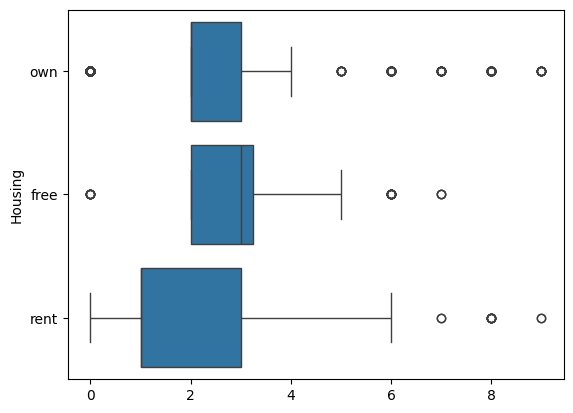

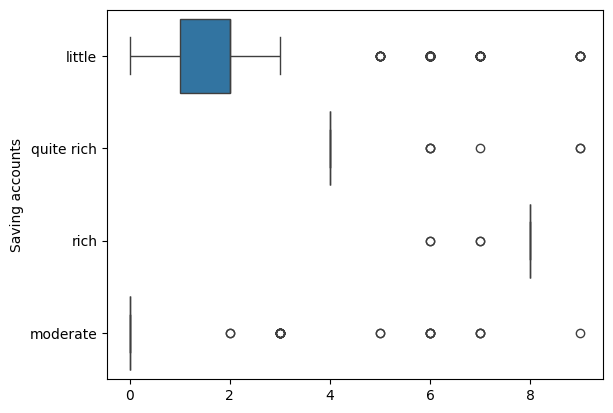

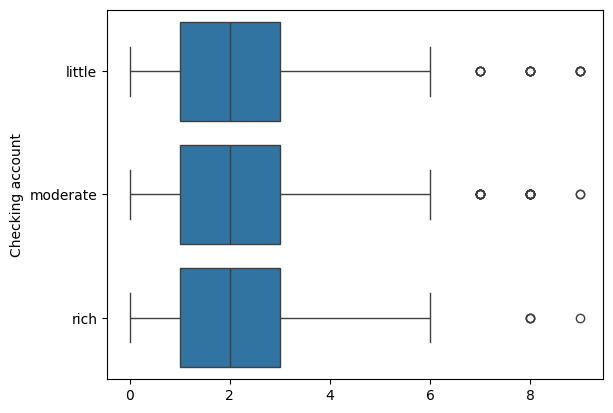

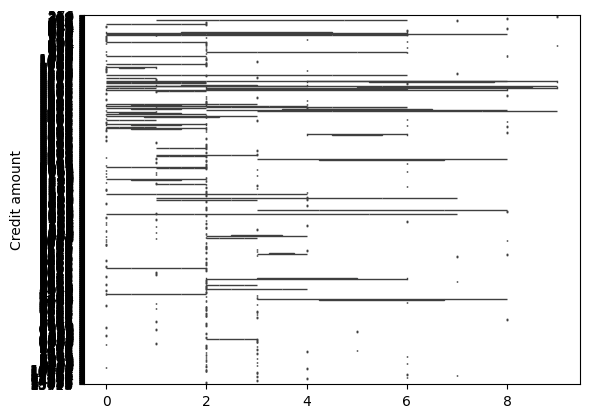

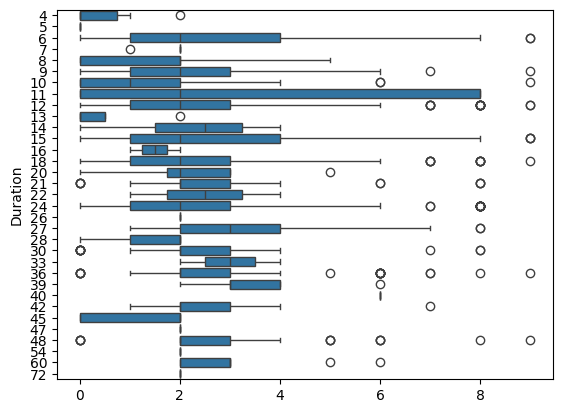

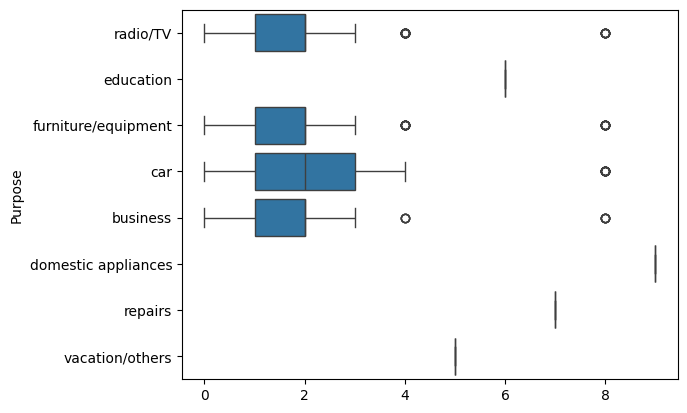

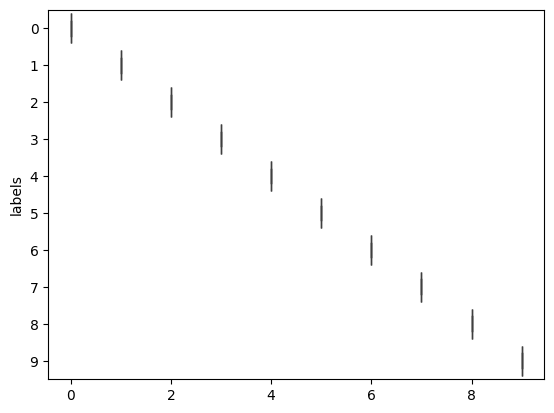

In [105]:
for col in data.columns:
    sns.boxplot(data=data, x=labels, y=col, orient='h')
    plt.show();

кластеров: 0


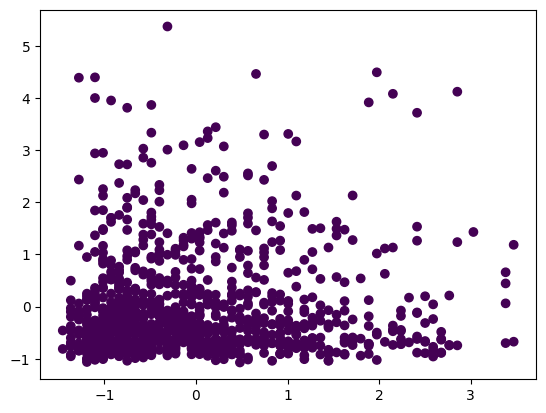

In [106]:
dbscan = DBSCAN(eps=0.2, min_samples=5).fit(X)
labels = dbscan.labels_
uniq_labels = np.unique(labels)
n_clusters = len(uniq_labels[uniq_labels != -1])
print(f'кластеров: {n_clusters}')
plt.scatter(X[:,0], X[:,1], c=labels);

In [107]:
dbscan = DBSCAN(eps=0.2, min_samples=20).fit(X)   # ядро нужно перезапустить, у вас NameError в этом классе
df = df.copy()
df['cluster'] = dbscan.labels_

df['cluster'].value_counts(dropna=False)  

cluster
-1    1000
Name: count, dtype: int64

In [113]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score
import matplotlib.pyplot as plt
import numpy as np

Число кластеров: 8
Шум: 589 (58.9%)
Silhouette score: 0.3013
Calinski-Harabasz: 83.99


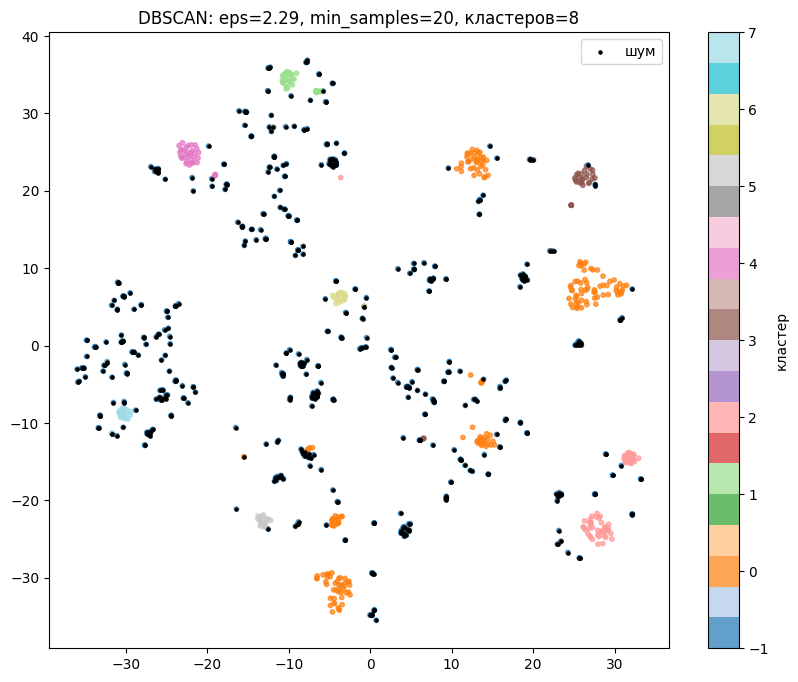

cluster_dbscan
-1    589
 0    191
 2     59
 4     36
 3     33
 1     31
 5     21
 7     20
 6     20
Name: count, dtype: int64


In [119]:
min_samples = 20
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels = dbscan.fit_predict(X)

n_clusters_ = len(set(labels) - {-1})
n_noise = int((labels == -1).sum())
print(f"Число кластеров: {n_clusters_}")
print(f"Шум: {n_noise} ({n_noise / len(labels) * 100:.1f}%)")

mask = labels != -1
if mask.sum() > 1 and n_clusters_ > 1:
    print(f"Silhouette score: {silhouette_score(X[mask], labels[mask]):.4f}")
    print(f"Calinski-Harabasz: {calinski_harabasz_score(X[mask], labels[mask]):.2f}")

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap='tab20', s=10, alpha=0.7)
plt.scatter(X_tsne[~mask, 0], X_tsne[~mask, 1], c='black', s=5, label='шум')
plt.colorbar(scatter, label='кластер')
plt.title(f"DBSCAN: eps={eps:.2f}, min_samples={min_samples}, кластеров={n_clusters_}")
plt.legend()
plt.show()

df = df.copy()
df['cluster_dbscan'] = labels
print(df['cluster_dbscan'].value_counts(dropna=False))

При eps взятый из локтя (20), собрано 8 кластеров

In [123]:
# Описание кластеров DBSCAN исходными признаками
desc = df_raw.copy()               # df_raw — с оригинальными категориальными колонками
desc['cluster_dbscan'] = labels    # та же индексация, что у df/X

num_cols = ['Age', 'Duration', 'Credit amount']
print("=== Числовые признаки (среднее) ===")
print(desc.groupby('cluster_dbscan')[num_cols].mean().round(1))

print("\n=== Числовые признаки (медиана) ===")
print(desc.groupby('cluster_dbscan')[num_cols].median().round(1))

print("\n=== Категоральные признаки (мода) ===")
cat_cols = ["Sex", "Job", "Housing", "Saving accounts", "Purpose"]
print(desc.groupby('cluster_dbscan')[cat_cols].agg(lambda s: s.mode().iloc[0]))

print("\n=== Доли категорий Purpose внутри кластеров ===")
print(pd.crosstab(desc['cluster_dbscan'], desc['Purpose'], normalize='index').round(2))

=== Числовые признаки (среднее) ===
                 Age  Duration  Credit amount
cluster_dbscan                               
-1              36.5      22.2         3686.0
 0              33.2      20.2         2769.6
 1              34.1      12.8         1493.6
 2              34.6      19.4         2858.8
 3              37.0      21.2         2537.5
 4              37.9      14.2         2221.8
 5              37.1      21.4         2494.6
 6              25.2      17.0         2588.1
 7              36.1      21.7         4418.6

=== Числовые признаки (медиана) ===
                 Age  Duration  Credit amount
cluster_dbscan                               
-1              34.0      18.0         2476.0
 0              31.0      18.0         2121.0
 1              28.0      12.0         1155.0
 2              32.0      18.0         2515.0
 3              36.0      18.0         2424.0
 4              38.5      12.0         1358.0
 5              36.0      20.0         2390.0
 6     